In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import cv2
import time
from tensorflow.keras import layers, models
from tensorflow.python.keras.layers import Dense

import os

In [2]:
#Function to convert a file path of audio sound to images
dataPath = "Dataset/raw_data"
outputPath = "Dataset/preprocessed"

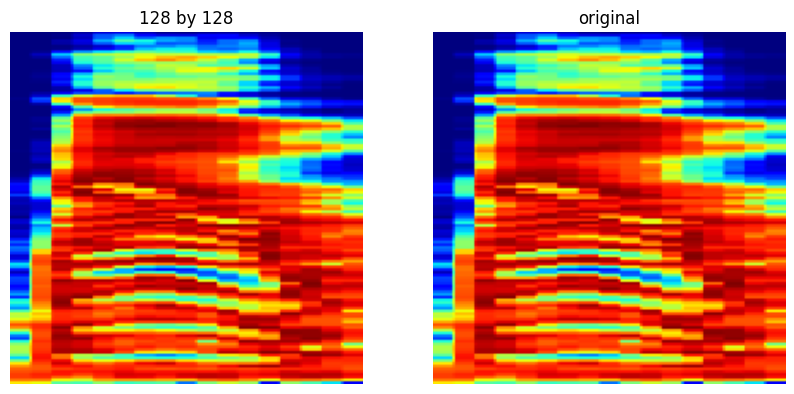

In [3]:
x = np.zeros((1,128,128))
tmp = cv2.imread("spectrogram.png",0) # 0 means gray scale

resize_tmp=cv2.resize(tmp,(128,128),interpolation=cv2.INTER_AREA) #AREA down sampling; linear slow but higher quality 
x[0]=resize_tmp

plt.figure(figsize=(10, 8))
plt.subplot(1,2,1)
plt.imshow(x[0],cmap='jet')
plt.title('128 by 128')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(resize_tmp,cmap='jet')
plt.title('original')
plt.axis('off')
plt.show()


In [4]:
import random

def augment_audio(y, sr=44100):
    """
    Returns a list of audio variants: [original, aug1, aug2, ...]
    Each variant will become a separate training sample.
    """
    augmented = [y]  # always keep original

    # 1. Time stretching (speeds up / slows down without pitch change)
    rate = random.uniform(0.8, 1.2)
    augmented.append(librosa.effects.time_stretch(y, rate=rate))

    # 2. Pitch shifting (semitones up or down)
    n_steps = random.randint(-3, 3)
    augmented.append(librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps))

    # 3. Time shifting (roll the waveform)
    shift = int(sr * random.uniform(0.1, 0.3))
    augmented.append(np.roll(y, shift))

    # 4. Gaussian noise (already have this — include for completeness)
    noise_factor = random.uniform(0.002, 0.008)
    augmented.append(y + noise_factor * np.random.randn(len(y)))

    return augmented  # 5 variants per file

In [ ]:

"""data=os.listdir(dataPath)[2]

folder=os.path.join(dataPath,data)
for e in os.scandir(folder):
    if e.is_file():
        print(e)"""
        
        
def AudioToImage(path,output_path,targetLabel='1'):
    
    """_summary_
        This function is responsible for converting the raw audio to images 
        inputs = file path 
        targetlabel = 1 (default)
    Returns:
        _type_: image matrix(np array), labels(np array) and total number of files(int)
    """
    for index, e in  enumerate(os.listdir(path)):
        if e == targetLabel: # find target path
             tl=index
        
    #check the target path
    t=os.listdir(path)[tl]
    targetFolder = os.path.join(dataPath,t)
    #check the other file path
    x=os.listdir(path)[tl-1]
    nontargetFolder = os.path.join(dataPath,x)
    
    if os.path.exists(targetFolder) and os.path.exists(nontargetFolder):
        target_files = [e for e in os.scandir(targetFolder) if e.is_file() and e.name.lower().endswith(".wav")]
        nontarget_files = [e for e in os.scandir(nontargetFolder) if e.is_file() and e.name.lower().endswith(".wav")]
        total_files = len(target_files) + len(nontarget_files)
        
        multiplier = 5  # number of augmented variants per file
        image = np.zeros((total_files * multiplier, 128, 128))
        label = np.zeros((total_files * multiplier,))
        counter=0
        
        for e in target_files:
            y_raw, sr = librosa.load(e)
            variants = augment_audio(y_raw, sr=44100)##########
            
            for y in variants:
                S_mel = librosa.feature.melspectrogram(
                y=y,
                sr=44100,
                n_fft=2048,        # FFT window size
                hop_length=512,     # step between windows
                n_mels=128,         # number of mel bands
                fmin=0,             # lowest frequency
                fmax=None,          # highest frequency (None = sr/2)
                power=2.0,          # 1 = energy, 2 = power
                )
                S_mel_db = librosa.power_to_db(S_mel, ref=np.max)
                
                fig, ax = plt.subplots(figsize=(10, 4))
                librosa.display.specshow(S_mel_db, sr=44100, hop_length=512,
                                        x_axis='time', y_axis='mel', ax=ax,cmap='jet')
                plt.axis('off')
                plt.tight_layout(pad=0)
                plt.savefig(f"{output_path}/spectrogram{counter}.png", dpi=300, bbox_inches='tight', pad_inches=0)
                plt.close()
                tmp=cv2.imread(f"{output_path}/spectrogram{counter}.png",0) # 0 means gray scale
                
                resize_tmp=cv2.resize(tmp,(128,128),interpolation=cv2.INTER_AREA) #AREA down sampling; linear slow but higher quality 
                image[counter]= resize_tmp
                label[counter]=1
                print(f"file done {e} {counter}")
                counter+=1
                del tmp,resize_tmp
            
        for e in nontarget_files:
            y, sr = librosa.load(e)
            variants = augment_audio(y_raw, sr=44100)##########
            
            for y in variants:
                #convert to spectrogram 
                S_mel = librosa.feature.melspectrogram(
                y=y,
                sr=44100,
                n_fft=2048,        # FFT window size
                hop_length=512,     # step between windows
                n_mels=128,         # number of mel bands
                fmin=0,             # lowest frequency
                fmax=None,          # highest frequency (None = sr/2)
                power=2.0,          # 1 = energy, 2 = power
                )
                S_mel_db = librosa.power_to_db(S_mel, ref=np.max)
                
                fig, ax = plt.subplots(figsize=(10, 4))
                librosa.display.specshow(S_mel_db, sr=44100, hop_length=512,
                                        x_axis='time', y_axis='mel', ax=ax,cmap='jet')
                plt.axis('off')
                plt.tight_layout(pad=0)
                plt.savefig(f"{output_path}/spectrogram{counter}.png", dpi=300, bbox_inches='tight', pad_inches=0)
                plt.close()
                tmp=cv2.imread(f"{output_path}/spectrogram{counter}.png",0) # 0 means gray scale
                # resize the image
                resize_tmp=cv2.resize(tmp,(128,128),interpolation=cv2.INTER_AREA) #AREA down sampling; linear slow but higher quality 

                image[counter]= resize_tmp
                label[counter]=0
                print(f"file done {e} {counter}")
                counter+=1
                del tmp,resize_tmp
        
        return image,label,total_files        
    else:
        print('here')
        return None
     
#testbench 
img,y,datapoints=AudioToImage(dataPath,outputPath)



file done <DirEntry 'help13.wav'> 0
file done <DirEntry 'help13.wav'> 1
file done <DirEntry 'help13.wav'> 2
file done <DirEntry 'help13.wav'> 3
file done <DirEntry 'help13.wav'> 4
file done <DirEntry 'help2_31.wav'> 5
file done <DirEntry 'help2_31.wav'> 6
file done <DirEntry 'help2_31.wav'> 7
file done <DirEntry 'help2_31.wav'> 8
file done <DirEntry 'help2_31.wav'> 9
file done <DirEntry 'help129.wav'> 10
file done <DirEntry 'help129.wav'> 11
file done <DirEntry 'help129.wav'> 12
file done <DirEntry 'help129.wav'> 13
file done <DirEntry 'help129.wav'> 14
file done <DirEntry 'help2_25.wav'> 15
file done <DirEntry 'help2_25.wav'> 16
file done <DirEntry 'help2_25.wav'> 17
file done <DirEntry 'help2_25.wav'> 18
file done <DirEntry 'help2_25.wav'> 19
file done <DirEntry 'help115.wav'> 20
file done <DirEntry 'help115.wav'> 21
file done <DirEntry 'help115.wav'> 22
file done <DirEntry 'help115.wav'> 23
file done <DirEntry 'help115.wav'> 24
file done <DirEntry 'help101.wav'> 25
file done <DirEnt

In [6]:
img.shape

(4200, 128, 128)

Normalise the data 

In [7]:
def spectrogram_augment(spec_2d):
    """spec_2d: (128,128) float array"""
    aug = spec_2d.copy()
    
    # Frequency masking — zero out a horizontal band
    f0 = random.randint(0, 20)
    f_start = random.randint(0, 128 - f0)
    aug[f_start:f_start + f0, :] = 0

    # Time masking — zero out a vertical band
    t0 = random.randint(0, 20)
    t_start = random.randint(0, 128 - t0)
    aug[:, t_start:t_start + t0] = 0

    return aug

In [12]:
from sklearn.preprocessing import StandardScaler
img_aug = np.array([spectrogram_augment(img[i]) for i in range(img.shape[0])])

flattened_data=np.reshape(img_aug,(4200,128*128))

scaler = StandardScaler()
scaler.fit(flattened_data)
input=scaler.transform(flattened_data)


Mel Spectrogram

In [13]:
tmp = input
print(tmp.shape)
print(y.shape)

(4200, 16384)
(4200,)


In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train,y_test = train_test_split(input,y,test_size=0.20,random_state=42)

In [15]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(3360, 16384)
(840, 16384)
(3360,)
(840,)


In [16]:
##RESHAPE FOR THE CNN

X_train_cnn = X_train.reshape(-1,128,128,1)
X_test_cnn = X_test.reshape(-1,128,128,1)


print(X_train_cnn.shape)
print(X_test_cnn.shape)

(3360, 128, 128, 1)
(840, 128, 128, 1)


In [17]:

def buildModel(inputShape=0):
    
    start = time.time()
    if inputShape == 0:
        return print("no input given")
    else:
        model = models.Sequential()
        model.add(layers.Conv2D(32,(3,3), activation='relu',input_shape=inputShape))# 32- feature detectors 
        model.add(layers.MaxPooling2D((2,2)))
        #second layer 
        model.add(layers.Conv2D(64,(3,3),activation='relu'))
        model.add(layers.MaxPooling2D((2,2)))
        #third layer
        model.add(layers.Conv2D(128,(3,3),activation='relu'))
        
        #flatten layer 
        model.add(layers.Flatten())
        model.add(layers.Dense(64,activation='relu'))
        model.add(layers.Dense(1,activation='sigmoid'))
        
        model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
        print("> Compilation Time : ", time.time() - start)
        model.summary()
        return model

In [18]:
X_train_cnn.shape[1:]

(128, 128, 1)

> Compilation Time :  0.20242881774902344


/Users/mac/Desktop/shu_msc/Artificial Intelligence/Assignment/AI_ASSIGNMENT/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     6,422,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,515,329 (24.85 MB)

 Trainable params: 6,515,329 (24.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 129ms/step - accuracy: 0.8862 - loss: 0.4084 - val_accuracy: 0.9762 - val_loss: 0.0610
Epoch 2/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.9847 - loss: 0.0543 - val_accuracy: 0.9940 - val_loss: 0.0354
Epoch 3/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.9940 - loss: 0.0249 - val_accuracy: 0.9940 - val_loss: 0.0421
Epoch 4/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 119ms/step - accuracy: 0.9978 - loss: 0.0170 - val_accuracy: 0.9940 - val_loss: 0.0515
Epoch 5/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.9978 - loss: 0.0145 - val_accuracy: 0.9940 - val_loss: 0.0432
Epoch 6/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 119ms/step - accuracy: 0.9978 - loss: 0.0103 - val_accuracy: 0.9926 - val_loss: 0.0641
Epoch 7/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.9970 - loss: 0.0092 - val_accuracy: 0.9940 - val_loss: 0.0581
Epoch 8/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.9978 - loss: 0.0077 - val_accu

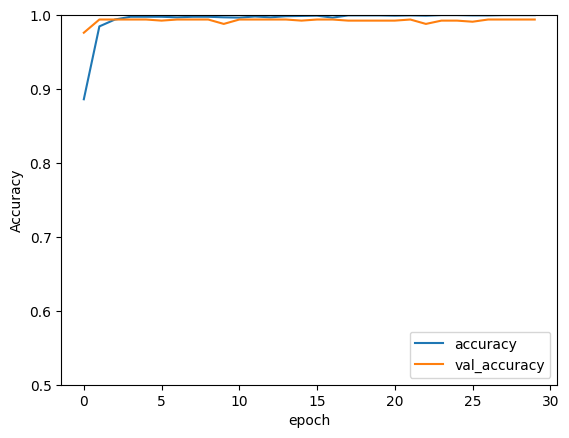

In [ ]:
model = buildModel(X_train_cnn.shape[1:])
history = model.fit(X_train_cnn,y_train,epochs=30,batch_size=32,validation_split=0.2,verbose=1)

plt.plot(history.history['accuracy'],label='accuracy')
plt.plot(history.history['val_accuracy'],label='val_accuracy')
plt.plot(history.history['loss'],label='loss')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5,1])
plt.legend(loc='lower right')

test_lost, test_accuracy = model.evaluate(X_test_cnn,y_test,verbose=1)

In [20]:
print(test_lost)
print(test_accuracy)

0.07348162680864334
0.9952380657196045


In [21]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
y_pred_probs = model.predict(X_test_cnn)
y_pred = (y_pred_probs > 0.5).astype(int).flatten() 
# ============================================
# Confusion Matrix
# ============================================
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion Matrix:")
print(cm)
print(f"\nTP={tp}, TN={tn}, FP={fp}, FN={fn}")

# ============================================
#Calculate all metrics
# ============================================
accuracy    = accuracy_score(y_test, y_pred)
precision   = precision_score(y_test, y_pred)
recall      = recall_score(y_test, y_pred)         # also called sensitivity
specificity = tn / (tn + fp)
f1          = f1_score(y_test, y_pred)

print(f"\nAccuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score:    {f1:.4f}")





27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
Confusion Matrix:
[[409   1]
 [  3 427]]

TP=427, TN=409, FP=1, FN=3

Accuracy:    0.9952
Precision:   0.9977
Recall:      0.9930
Specificity: 0.9976
F1 Score:    0.9953


In [22]:
# ============================================
#Full classification report (handy summary)
# ============================================
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Not Help', 'Help']))


Classification Report:
              precision    recall  f1-score   support

    Not Help       0.99      1.00      1.00       410
        Help       1.00      0.99      1.00       430

    accuracy                           1.00       840
   macro avg       1.00      1.00      1.00       840
weighted avg       1.00      1.00      1.00       840



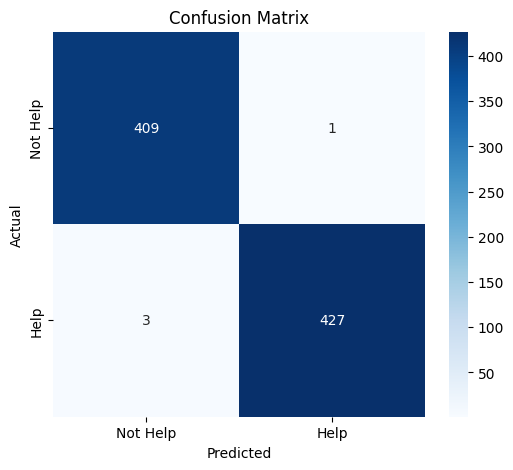

In [23]:
# ============================================
# STEP 5: Visualise the confusion matrix
# ============================================
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Help','Help'],
            yticklabels=['Not Help','Help'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

> Compilation Time :  0.20064091682434082


/Users/mac/Desktop/shu_msc/Artificial Intelligence/Assignment/AI_ASSIGNMENT/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     6,422,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,515,329 (24.85 MB)

 Trainable params: 6,515,329 (24.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 127ms/step - accuracy: 0.9193 - loss: 0.3011 - val_accuracy: 0.9807 - val_loss: 0.0705
Epoch 2/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.9877 - loss: 0.0432 - val_accuracy: 0.9911 - val_loss: 0.0441
Epoch 3/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - accuracy: 0.9978 - loss: 0.0193 - val_accuracy: 0.9940 - val_loss: 0.0494
Epoch 4/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 116ms/step - accuracy: 0.9974 - loss: 0.0144 - val_accuracy: 0.9940 - val_loss: 0.0690
Epoch 5/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 116ms/step - accuracy: 0.9978 - loss: 0.0121 - val_accuracy: 0.9940 - val_loss: 0.0677
Epoch 6/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.9978 - loss: 0.0098 - val_accuracy: 0.9940 - val_loss: 0.0632
Epoch 7/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 141ms/step - accuracy: 0.9981 - loss: 0.0074 - val_accuracy: 0.9940 - val_loss: 0.0960
Epoch 8/30
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 163ms/step - accuracy: 0.9981 - loss: 0.0079 - val_accu

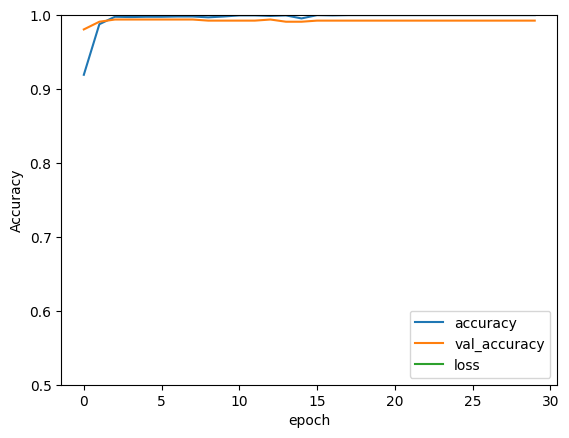

In [24]:
model = buildModel(X_train_cnn.shape[1:])
history = model.fit(X_train_cnn,y_train,epochs=30,batch_size=32,validation_split=0.2,verbose=1)

plt.plot(history.history['accuracy'],label='accuracy')
plt.plot(history.history['val_accuracy'],label='val_accuracy')
plt.plot(history.history['loss'],label='loss')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5,1])
plt.legend(loc='lower right')

test_lost, test_accuracy = model.evaluate(X_test_cnn,y_test,verbose=1)

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9929 - loss: 0.1035


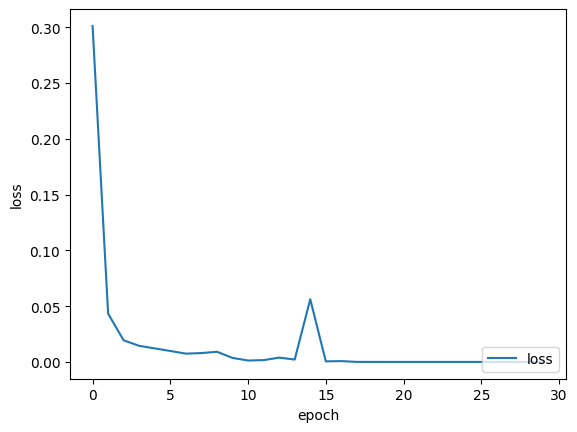

In [26]:
plt.plot(history.history['loss'],label='loss')
plt.xlabel('epoch')
plt.ylabel('loss')

plt.legend(loc='lower right')

test_lost, test_accuracy = model.evaluate(X_test_cnn,y_test,verbose=1)